# Whiteboard glare & shadow removal
White balancing (He & Zhang) followed by sharpening and intensity scaling (CleanPage). No loops over pixels, just numpy / OpenCV array operations.

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Step 1: White balancing

In [17]:
def estimate_background(img, block=24, percentile=90):
    """Estimate the empty-board colour (no ink) using one value per block."""
    h, w = img.shape[:2]
    bh, bw = -(-h // block), -(-w // block)  # ceil division

    # Pad so the image splits evenly, then give each block its own pixel axis
    padded = np.pad(img, ((0, bh * block - h), (0, bw * block - w), (0, 0)), mode="edge")
    blocks = (padded.reshape(bh, block, bw, block, 3)
                    .transpose(0, 2, 1, 3, 4)
                    .reshape(bh, bw, block * block, 3))

    # Bright percentile of each block = board colour (ink is the minority)
    grid = np.percentile(blocks, percentile, axis=2).astype(np.uint8)

    # Ink-heavy blocks come out too dark: swap in the neighbourhood median if brighter
    grid = np.maximum(grid, cv2.medianBlur(grid, 9))

    # Smooth and scale back up to full size
    grid = cv2.GaussianBlur(grid.astype(np.float32), (0, 0), 2)
    return np.maximum(cv2.resize(grid, (w, h), interpolation=cv2.INTER_CUBIC), 1)


def white_balance(img, bg, saturation=1.4):
    """Divide out the background colour, then boost saturation."""
    out = np.clip(img / bg * 255, 0, 255).astype(np.uint8)
    hsv = cv2.cvtColor(out, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 1] = np.clip(hsv[..., 1] * saturation, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

## Step 2: Image enhancement

In [18]:
def yen_threshold(gray):
    """Yen's automatic threshold (separates ink from board)."""
    p = np.bincount(gray.ravel(), minlength=256) / gray.size
    p1 = np.cumsum(p)
    lo_sq = np.cumsum(p ** 2)
    hi_sq = lo_sq[-1] - lo_sq
    eps = 1e-12
    crit = -np.log(np.maximum(lo_sq * hi_sq, eps)) + 2 * np.log(np.maximum(p1 * (1 - p1), eps))
    return np.argmax(crit)


def intensity_scale(img):
    """Make the board pure white."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    board = gray[gray > yen_threshold(gray)]
    white = max(np.median(board) * 0.97, 1) if board.size else 255
    return np.clip(img.astype(np.float32) / white * 255, 0, 255).astype(np.uint8)


def sharpen(img):
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]], dtype=np.float32)
    return cv2.filter2D(img, -1, kernel)


def clean_whiteboard(img):
    bg = estimate_background(img)
    balanced = white_balance(img.astype(np.float32), bg)
    return bg.astype(np.uint8), sharpen(intensity_scale(balanced))

## Run it

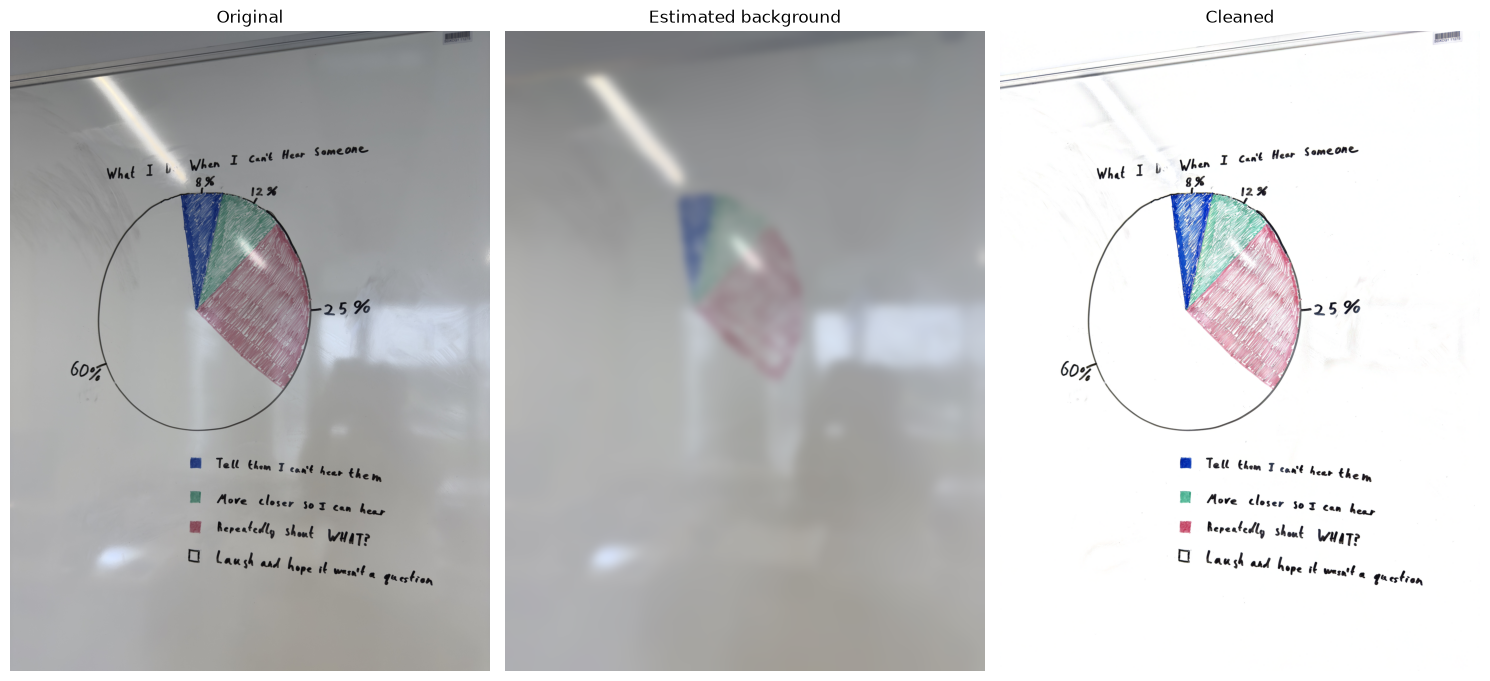

In [19]:
path = "../../sample-images/IMG_1294.jpg"

img = cv2.imread(path)
if img is None:
    raise FileNotFoundError(f"Could not read {path}")

# img = deskew(img)   # <-- your deskew step
bg, result = clean_whiteboard(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, im, title in zip(axes, [img, bg, result],
                         ["Original", "Estimated background", "Cleaned"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()